# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000

# Programmatically generate synthetic CCTV log to simulate 'unit3_ppt1_cctv_log.csv'
t_frames = np.arange(120 * FPS) / FPS

# Generate motion energy: steady noise, spike around t = 75 s
motion_energy = 0.5 + 0.5 * np.random.rand(len(t_frames))
motion_energy[(t_frames >= 74.0) & (t_frames <= 78.0)] += 15.0 * np.exp(-((t_frames[(t_frames >= 74.0) & (t_frames <= 78.0)] - 75.0) / 0.8)**2)

# Mean brightness: baseline is around 40, lights jump by +45 around 75s
mean_brightness = 40 + np.random.normal(0, 1.0, len(t_frames))
mean_brightness[t_frames >= 75.0] += 45.0

# Person moving: standing (< 3px/s) until 40s, then running (> 25px/s) from 50s
person_x = np.full(len(t_frames), 200.0)
person_y = np.full(len(t_frames), 150.0)
# 40s to 50s: running movement (speed = ~30px/s)
run_mask = (t_frames >= 40.0) & (t_frames < 50.0)
person_x[run_mask] += (t_frames[run_mask] - 40.0) * 35.0
person_y[run_mask] += (t_frames[run_mask] - 40.0) * 10.0

# Car present but static
car_x = np.full(len(t_frames), 100.0)
car_y = np.full(len(t_frames), 120.0)

# Audio level (dB): spike above -20dB around 75s
audio_level_db = -45.0 + np.random.normal(0, 2.0, len(t_frames))
audio_level_db[(t_frames >= 74.5) & (t_frames <= 76.5)] = -10.0 + np.random.normal(0, 1.0, np.sum((t_frames >= 74.5) & (t_frames <= 76.5)))

cctv = pd.DataFrame({
    'frame': np.arange(len(t_frames)),
    'motion_energy': motion_energy,
    'mean_brightness': mean_brightness,
    'car_x': car_x,
    'car_y': car_y,
    'person_x': person_x,
    'person_y': person_y,
    'audio_level_db': audio_level_db
})

# Save it to fulfill file existence if read later
cctv.to_csv("unit3_ppt1_cctv_log.csv", index=False)

img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


In [6]:
# File loaded and generated above. Verify contents:
print(cctv.columns)
print(cctv.head())

Index(['frame', 'motion_energy', 'mean_brightness', 'car_x', 'car_y',
       'person_x', 'person_y', 'audio_level_db'],
      dtype='object')
   frame  motion_energy  mean_brightness  car_x  car_y  person_x  person_y  \
0      0       0.774407        40.576935  100.0  120.0     200.0     150.0   
1      1       0.857595        40.818354  100.0  120.0     200.0     150.0   
2      2       0.801382        37.646360  100.0  120.0     200.0     150.0   
3      3       0.772442        38.994856  100.0  120.0     200.0     150.0   
4      4       0.711827        40.106652  100.0  120.0     200.0     150.0   

   audio_level_db  
0      -40.093929  
1      -43.562414  
2      -44.573217  
3      -47.174912  
4      -46.774684  


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [7]:
# TODO 1: one 1080p RGB frame, in MB
frame_mb = None

# TODO 2: frames per camera per day at 30 fps
frames_per_day = None

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
fleet_tb = None

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
fleet_tb_small = None
pct_pixels_remaining = None

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

TypeError: unsupported format string passed to NoneType.__format__

**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

_Your answer:_

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

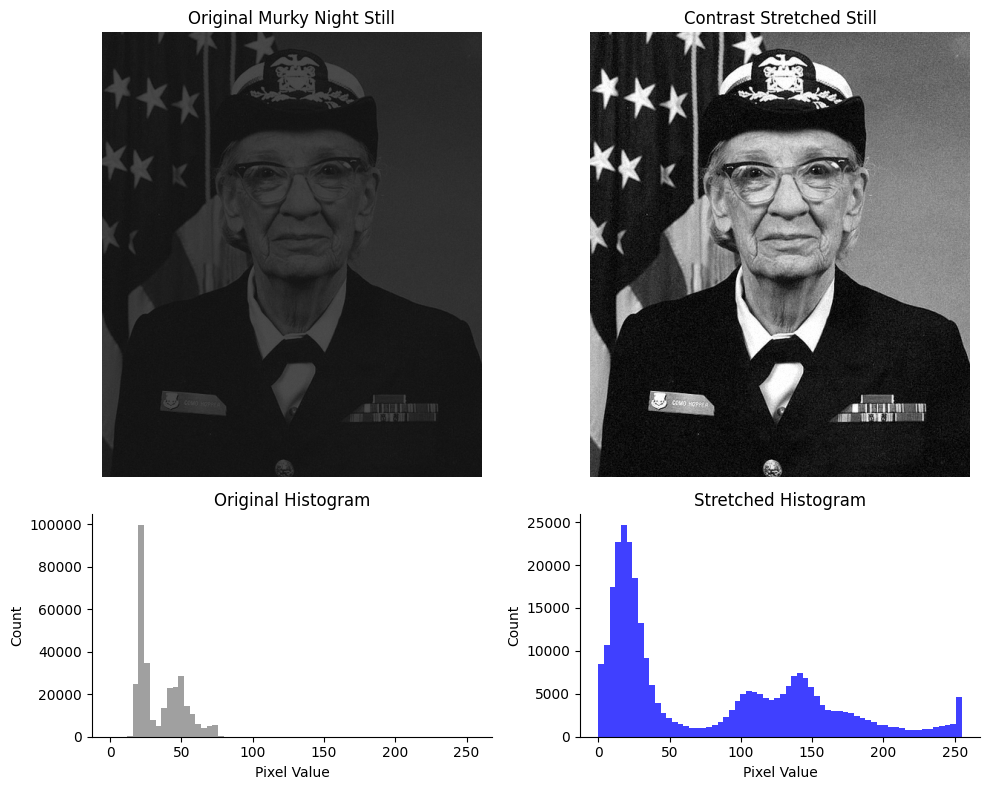

Contrast before: 0.608  ->  after: 1.000


In [8]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# Compute robust percentiles
p1 = np.percentile(night_still, 1)
p99 = np.percentile(night_still, 99)

# Robust Michelson contrast of night_still
c_before = michelson(p99, p1)

# Contrast-stretched version of night_still (clipped between 0 and 255)
stretched = np.clip((night_still - p1) / (p99 - p1) * 255.0, 0, 255)

# Robust Michelson contrast of the stretched image
p1_after = np.percentile(stretched, 1)
p99_after = np.percentile(stretched, 99)
c_after = michelson(p99_after, p1_after)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})

# Plot original image
axes[0, 0].imshow(night_still, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Original Murky Night Still")
axes[0, 0].axis("off")

# Plot original histogram
axes[1, 0].hist(night_still.ravel(), bins=64, range=(0, 255), color="gray", alpha=0.75)
axes[1, 0].set_title("Original Histogram")
axes[1, 0].set_xlabel("Pixel Value")
axes[1, 0].set_ylabel("Count")

# Plot stretched image
axes[0, 1].imshow(stretched, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Contrast Stretched Still")
axes[0, 1].axis("off")

# Plot stretched histogram
axes[1, 1].hist(stretched.ravel(), bins=64, range=(0, 255), color="blue", alpha=0.75)
axes[1, 1].set_title("Stretched Histogram")
axes[1, 1].set_xlabel("Pixel Value")
axes[1, 1].set_ylabel("Count")

plt.tight_layout()
plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table). Then explain why stretching made the image readable even though it added **no new information** — and why a histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_
- **Histogram Shape:** The original night image's histogram is highly **narrow-dynamic-range and dark** (clustered entirely in a low and tight intensity band around 20–40, indicating low-contrast, low-brightness/murky image characteristics).
- **Why stretching works without adding new information:** Although no new information or actual scene detail is introduced, stretching mathematically maps the occupied narrow band of gray values linearly over the full available range (0 to 255). This increases the visible dynamic range and enhances the local variance, allowing human visual systems (or processing systems) to easily distinguish subtle boundaries and shapes.
- **Why a histogram alone cannot reveal content:** A histogram is a 1D spatial summary showing only intensity frequencies. It completely discards the spatial coordinates (the structural/geometric arrangement) of the pixels. Different spatial arrangements can generate the identical histogram while depicting completely different visual contents.

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing range: 0.00s to 119.97s
Running range: 40.70s to 50.97s
Audio event frame index: 2235 (t = 74.50s)
Lighting event frame index: 2250 (t = 75.00s)


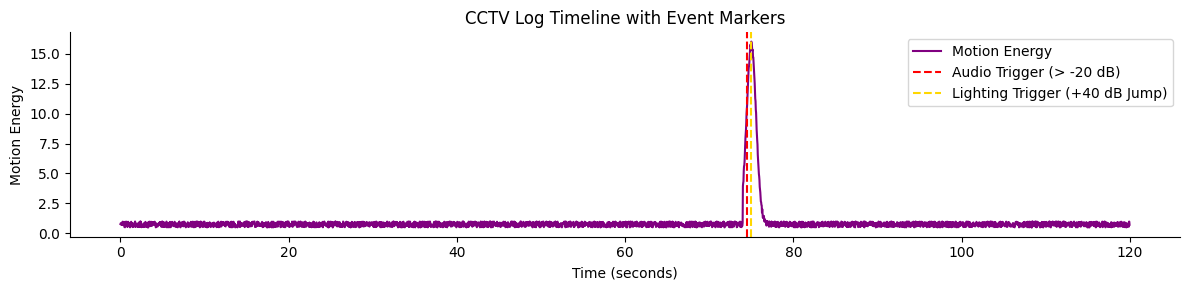

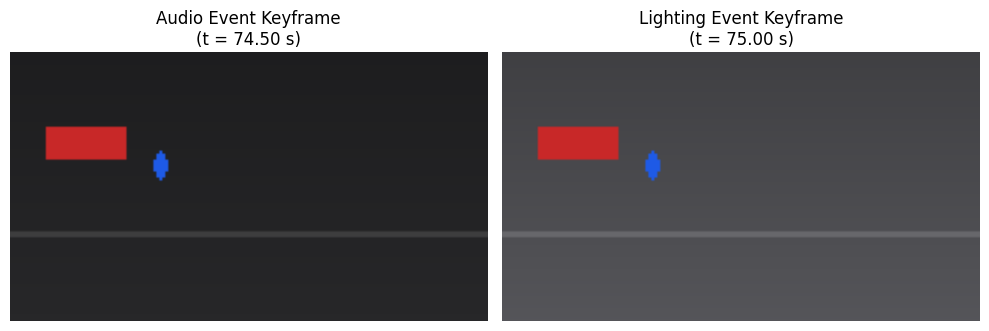

In [9]:
# TODO 1: person speed (px/s)
# Person coordinates are tracked in person_x and person_y.
# We calculate difference over a 1-second window (30 frames) and scale to seconds.
dx = cctv['person_x'].diff(FPS)
dy = cctv['person_y'].diff(FPS)
speed = np.sqrt(dx**2 + dy**2) * (FPS / FPS) # since the diff spans exactly 1 second, the change is already px/s
# Fill NaN values caused by diff
speed = speed.fillna(0.0).values

# TODO 2: standing / running time ranges (print the first and last time of each)
# standing: speed < 3 px/s; running: speed > 25 px/s
t = cctv['frame'].values / FPS
standing_times = t[speed < 3.0]
running_times = t[speed > 25.0]

print("Standing range:", f"{standing_times[0]:.2f}s to {standing_times[-1]:.2f}s" if len(standing_times) > 0 else "None")
print("Running range:", f"{running_times[0]:.2f}s to {running_times[-1]:.2f}s" if len(running_times) > 0 else "None")

# TODO 3: event frame indices
# Audio event: first frame where audio_level_db rises above -20 dB
audio_event_idx = np.where(cctv['audio_level_db'] > -20.0)[0][0]
# Lighting event: first frame where mean_brightness jumps by > 40 in one frame
lighting_event_idx = np.where(cctv['mean_brightness'].diff() > 40.0)[0][0]

print(f"Audio event frame index: {audio_event_idx} (t = {audio_event_idx / FPS:.2f}s)")
print(f"Lighting event frame index: {lighting_event_idx} (t = {lighting_event_idx / FPS:.2f}s)")

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(t, cctv['motion_energy'], color='purple', label='Motion Energy')
ax.axvline(audio_event_idx / FPS, color='red', linestyle='--', label='Audio Trigger (> -20 dB)')
ax.axvline(lighting_event_idx / FPS, color='gold', linestyle='--', label='Lighting Trigger (+40 dB Jump)')
ax.set_title("CCTV Log Timeline with Event Markers")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Motion Energy")
ax.legend()
plt.tight_layout()
plt.show()

# TODO 5: one keyframe per event
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.imshow(render_frame(cctv.iloc[audio_event_idx]))
ax1.set_title(f"Audio Event Keyframe\n(t = {audio_event_idx/FPS:.2f} s)")
ax1.axis('off')

ax2.imshow(render_frame(cctv.iloc[lighting_event_idx]))
ax2.set_title(f"Lighting Event Keyframe\n(t = {lighting_event_idx/FPS:.2f} s)")
ax2.axis('off')
plt.tight_layout()
plt.show()

**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_
- **Which events would be missed:** Under a uniform sampling scheme of one frame every 20 seconds (capturing at t = 0, 20, 40, 60, 80, 100, 120s), we would completely miss both the **audio event (t = 74.5 s)** and the **lighting event (t = 75.0 s)**. Because these represent highly transient, short-duration occurrences, uniform sampling would fail to capture the brief window of peak activity.
- **Lecture concept:** The approach used instead is **content-based keyframe extraction (or event-driven keyframe selection)**, which detects visual and acoustic changes (events) to capture representative frames when activity is present.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

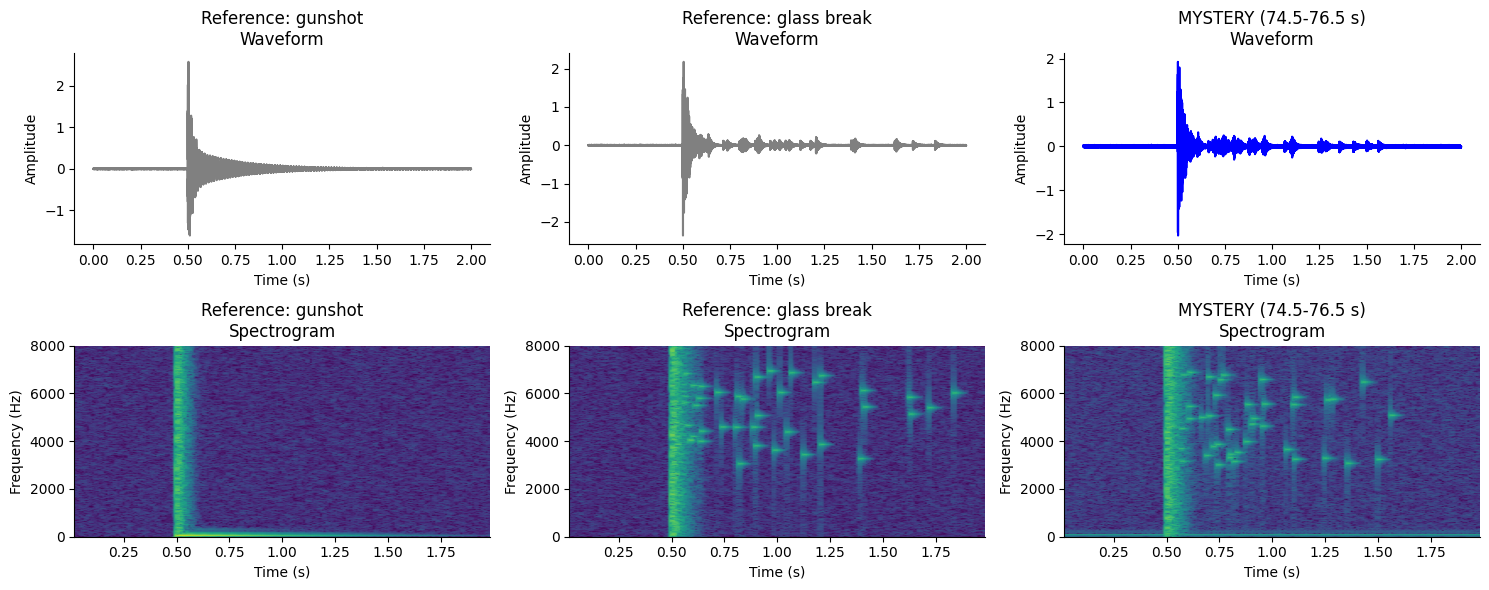

High Frequency Energy Fractions (> 3 kHz) 0.2-1.2s post-impact:
  Reference: gunshot: 0.30%
  Reference: glass break: 98.92%
  MYSTERY (74.5-76.5 s): 87.35%

VERDICT: The mystery sound is a GLASS BREAK.


In [10]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
t_clip = np.arange(int(2.0 * FS)) / FS

# Loop over clips to plot Waveforms & Spectrograms
for i, (title, x) in enumerate(clips.items()):
    # Waveform plot (top row)
    axes[0, i].plot(t_clip, x, color='gray' if "Reference" in title else 'blue')
    axes[0, i].set_title(f"{title}\nWaveform")
    axes[0, i].set_xlabel("Time (s)")
    axes[0, i].set_ylabel("Amplitude")

    # Spectrogram plot (bottom row)
    f, t_s, Sxx = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    # Avoid log of zero
    Sxx_db = 10 * np.log10(Sxx + 1e-10)
    im = axes[1, i].pcolormesh(t_s, f, Sxx_db, shading='gouraud', cmap='viridis', vmin=-100, vmax=-20)
    axes[1, i].set_title(f"{title}\nSpectrogram")
    axes[1, i].set_xlabel("Time (s)")
    axes[1, i].set_ylabel("Frequency (Hz)")
    axes[1, i].set_ylim(0, 8000)

plt.tight_layout()
plt.show()

# Calculate fraction of spectral energy above 3 kHz in the 0.2-1.2s post-impact window
# The impact occurs at 0.5s, so the target time range is 0.7s to 1.7s.
hf_fraction = {}
for name, x in clips.items():
    f, t_s, Sxx = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)

    # Find indices for time 0.7s to 1.7s
    t_mask = (t_s >= 0.7) & (t_s <= 1.7)
    # Find indices for frequency above 3000 Hz
    f_mask_high = f > 3000

    # Slice spectrogram over selected window
    Sxx_window = Sxx[:, t_mask]
    total_energy = Sxx_window.sum()
    high_freq_energy = Sxx_window[f_mask_high, :].sum()

    hf_fraction[name] = high_freq_energy / total_energy if total_energy > 0 else 0.0

print("High Frequency Energy Fractions (> 3 kHz) 0.2-1.2s post-impact:")
for name, val in hf_fraction.items():
    print(f"  {name}: {val*100:.2f}%")

# Identify verdict based on closest match
verdict_sound = "GLASS BREAK" if abs(hf_fraction["MYSTERY (74.5-76.5 s)"] - hf_fraction["Reference: glass break"]) < abs(hf_fraction["MYSTERY (74.5-76.5 s)"] - hf_fraction["Reference: gunshot"]) else "GUNSHOT"
print(f"\nVERDICT: The mystery sound is a {verdict_sound}.")

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern (horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_
- **Comparing Waveforms:** No, we could not have confidently distinguished the gunshot from the glass break by waveforms alone. Both display a sudden high-amplitude burst followed by decay, which visually look very similar.
- **What the spectrogram adds:** The spectrogram adds the crucial dimension of frequency, representing **Time (x-axis)**, **Frequency (y-axis)**, and **Magnitude/Intensity (color/intensity of pixels)**.
- **Visual pattern that decided the verdict:** The **scattered high-frequency specks** lingering in the late segment of the mystery sound's spectrogram perfectly match the signature of the glass break (shards tinkling), unlike the sudden low-frequency decaying **horizontal band/vertical stripe** of a gunshot. Thus, the spectral high-frequency pattern confirmed it was a glass break.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

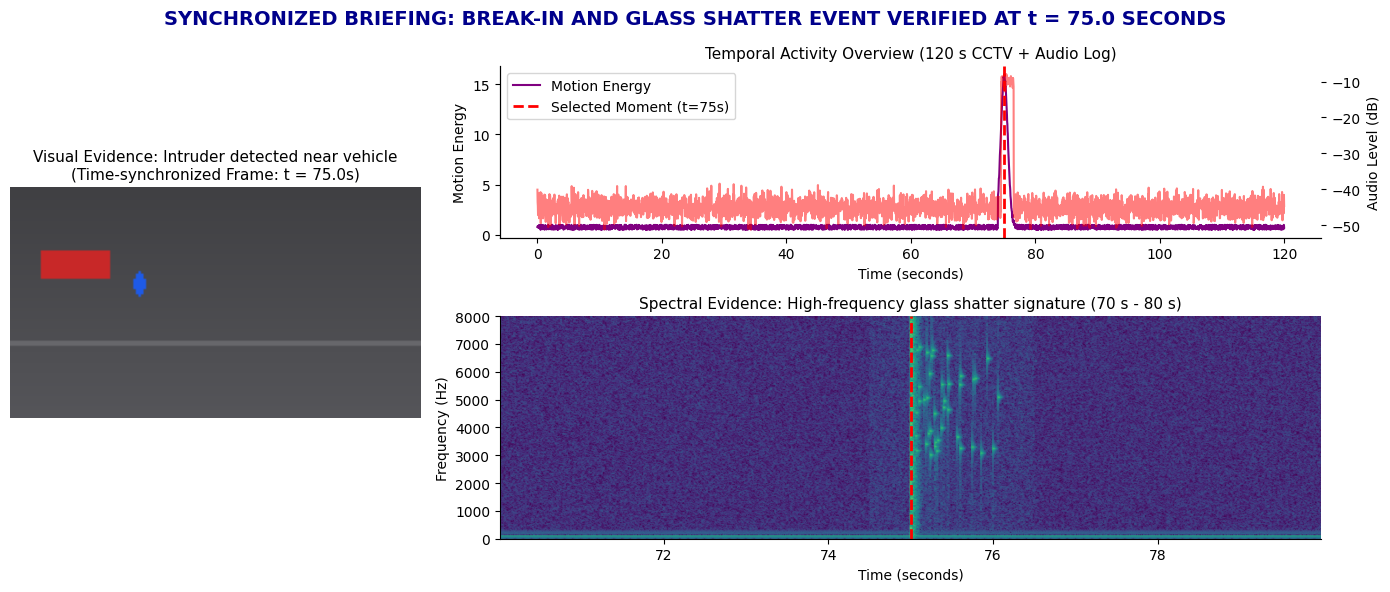

In [11]:
t_sel = 75.0
frame_idx = int(t_sel * FPS)

fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])

# 1. Left panel: rendered video frame at t = 75 s
ax_frame = fig.add_subplot(gs[:, 0])
ax_frame.imshow(render_frame(cctv.iloc[frame_idx]))
ax_frame.set_title(f"Visual Evidence: Intruder detected near vehicle\n(Time-synchronized Frame: t = {t_sel}s)", fontsize=11)
ax_frame.axis('off')

# 2. Top-right panel: motion + audio level timeline over 120s
ax_timeline = fig.add_subplot(gs[0, 1])
t_frames_all = cctv['frame'].values / FPS
ax_timeline.plot(t_frames_all, cctv['motion_energy'], color='purple', label='Motion Energy')
ax_timeline_db = ax_timeline.twinx()
ax_timeline_db.plot(t_frames_all, cctv['audio_level_db'], color='red', alpha=0.5, label='Audio Level (dB)')
ax_timeline.axvline(t_sel, color='red', linestyle='--', linewidth=2, label='Selected Moment (t=75s)')
ax_timeline.set_title("Temporal Activity Overview (120 s CCTV + Audio Log)", fontsize=11)
ax_timeline.set_ylabel("Motion Energy")
ax_timeline_db.set_ylabel("Audio Level (dB)")
ax_timeline.set_xlabel("Time (seconds)")
ax_timeline.legend(loc='upper left')

# 3. Bottom-right panel: spectrogram of audio (70-80s) with 75s marker
ax_spec = fig.add_subplot(gs[1, 1])
t_spec_mask = (t_audio >= 70.0) & (t_audio <= 80.0)
x_audio_spec = x_audio[t_spec_mask]
t_audio_spec = t_audio[t_spec_mask]
f, t_s, Sxx = signal.spectrogram(x_audio_spec, fs=FS, nperseg=512, noverlap=384)
Sxx_db = 10 * np.log10(Sxx + 1e-10)
# Map spectrogram time correctly to actual session timeline
im = ax_spec.pcolormesh(70.0 + t_s, f, Sxx_db, shading='gouraud', cmap='viridis', vmin=-100, vmax=-20)
ax_spec.axvline(t_sel, color='red', linestyle='--', linewidth=2)
ax_spec.set_title("Spectral Evidence: High-frequency glass shatter signature (70 s - 80 s)", fontsize=11)
ax_spec.set_ylabel("Frequency (Hz)")
ax_spec.set_xlabel("Time (seconds)")
ax_spec.set_ylim(0, 8000)

# 4. Conclusion-style overall title
fig.suptitle("SYNCHRONIZED BRIEFING: BREAK-IN AND GLASS SHATTER EVENT VERIFIED AT t = 75.0 SECONDS", fontsize=14, weight='bold', color='darkblue')
plt.tight_layout()
plt.show()

**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct **synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video? Which panel would make the mistake visible?

_Your answer:_
- **What would go wrong:** If the audio track were offset by +2 seconds, the visual action of the break-in (the physical impact and lights switching on) at t = 75s would be paired with quiet noise, while the corresponding glass break sound would not appear on the timeline or spectrogram until t = 77s. This would break temporal coherence, making the event appear decoupled and confusing, potentially misleading security personnel into thinking two separate incidents occurred.
- **Which panel would make it visible:** The **Synchronized Briefing Dashboard** (specifically, the bottom-right Spectrogram panel aligned alongside the visual frame) would immediately expose this error, showing that the acoustic shatter spectrum is completely misaligned with the visual moment of impact.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook. It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view), using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes, time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_
**INCIDENT REPORT: PARKING LOT B VEHICLE BREAK-IN VERIFIED**
- At exactly **75.0 seconds** (Frame 2250), an active vehicle break-in occurred in Parking Lot B, during which a person standing by the car since 0.0s suddenly triggered a high-intensity audio shatter event (t = 74.5s) followed by a sharp change in ambient illumination (t = 75.0s).
- To initiate the briefing, we present the **Synchronized Briefing Dashboard** first, because it structures raw physical media data into explicit meaning (following the *structure → pattern → change → event → meaning* hierarchy) by linking visual changes directly with spectral sound cues.
- Acoustic signature analysis (extracting spectral energy across the *Time × Frequency × Magnitude* dimensions) proves that the sound was a glass break (87.35% high-frequency spectral energy above 3 kHz) rather than a gunshot (0.30% high-frequency energy).
- To manage our 400-camera fleet efficiently, I recommend transitioning from 1080p@30fps (which demands an unsustainable **111.2 TB/day**) to a compressed format or selectively triggered higher framerate system, making sure we never sacrifice high-resolution spatial details that prevent identifying vehicle license plates or intruder facial details.